In [4]:
import numpy as np

X = np.loadtxt("./dataset/train_x.txt", delimiter=",")
Y = np.loadtxt("./dataset/train_y.txt", delimiter=",")

print("RSS shape:", X.shape)
print("GPS shape:", Y.shape)
# Check dataset alignment
assert X.shape[0] == Y.shape[0]
# RSS threshold
RSS_THRESHOLD = -100

# Convert RSS values into binary sequences
X_binary = (X >= RSS_THRESHOLD).astype(np.uint8)

print("Original RSS shape:", X.shape)
print("Binary RSS shape:", X_binary.shape)
print("GPS shape:", Y.shape)

print("\nFirst original RSS observation:")
print(X[0])

print("\nFirst binary observation:")
print(X_binary[0])

print("\nFirst GPS coordinate:")
print(Y[0])

# Count active access points per observation
active_aps = X_binary.sum(axis=1)

print("\nAverage active APs:", active_aps.mean())
print("Minimum active APs:", active_aps.min())
print("Maximum active APs:", active_aps.max())

# Check missing and invalid values
print("\nMissing RSS values:", np.isnan(X).sum())
print("Missing GPS values:", np.isnan(Y).sum())



RSS shape: (5500, 21)
GPS shape: (5500, 2)
Original RSS shape: (5500, 21)
Binary RSS shape: (5500, 21)
GPS shape: (5500, 2)

First original RSS observation:
[ -77.  -57. -108.  -75.  -77. -108. -108.  -77. -108. -108. -108. -108.
  -77. -108. -108. -108. -108. -108.  -79. -108. -108.]

First binary observation:
[1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0]

First GPS coordinate:
[31.265377 30.003767]

Average active APs: 6.982545454545455
Minimum active APs: 6
Maximum active APs: 7

Missing RSS values: 0
Missing GPS values: 0


In [5]:
import numpy as np
import pandas as pd
class LocalizationDataset:

    def __init__(self, rss_file, gps_file, threshold=-100):
        self.X = np.loadtxt(rss_file, delimiter=",")
        self.Y = np.loadtxt(gps_file, delimiter=",")

        if len(self.X) != len(self.Y):
            raise ValueError("RSS and GPS records are not aligned")

        if not np.isfinite(self.X).all():
            raise ValueError("RSS contains invalid values")

        if not np.isfinite(self.Y).all():
            raise ValueError("GPS contains invalid values")

        self.threshold = threshold

        # Preserve all original observations
        self.binary = (self.X >= threshold).astype(np.uint8)

        self.data = pd.DataFrame({
            "record_id": np.arange(len(self.X)),
            "binary_sequence": list(self.binary),
            "latitude": self.Y[:, 0],
            "longitude": self.Y[:, 1]
        })

    def summary(self):
        print("Total observations:", len(self.X))
        print("Access points:", self.X.shape[1])
        print("GPS records:", len(self.Y))
        print("Binary shape:", self.binary.shape)
        print("Unique GPS locations:",
              len(np.unique(self.Y, axis=0)))

    def get_reference_database(self):
        # Keep every observation, including repeated GPS coordinates
        return self.data.copy()

In [6]:
dataset = LocalizationDataset(
        "./dataset/train_x.txt",
        "./dataset/train_y.txt"
    )

dataset.summary()

reference_db = dataset.get_reference_database()

reference_db.to_pickle("localization_reference.pkl")

print("\nReference database saved.")
print(reference_db.head())

Total observations: 5500
Access points: 21
GPS records: 5500
Binary shape: (5500, 21)
Unique GPS locations: 11

Reference database saved.
   record_id                                    binary_sequence   latitude  \
0          0  [1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, ...  31.265377   
1          1  [1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, ...  31.264477   
2          2  [1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, ...  31.264477   
3          3  [1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, ...  31.264477   
4          4  [1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, ...  31.264477   

   longitude  
0  30.003767  
1  30.004704  
2  30.004704  
3  30.004704  
4  30.004704  


In [7]:
class HammingDistance:

    @staticmethod
    def calculate(query, reference):
        query = np.asarray(query, dtype=np.uint8)
        reference = np.asarray(reference, dtype=np.uint8)

        if query.shape != reference.shape:
            raise ValueError("Sequence dimensions must match")

        return int(np.count_nonzero(query != reference))

    @staticmethod
    def compare_database(query, reference_db):
        references = np.stack(
            reference_db["binary_sequence"].to_numpy()
        )

        # Compare query with all reference observations
        distances = np.count_nonzero(
            references != query,
            axis=1
        )

        results = reference_db[
            ["record_id", "latitude", "longitude"]
        ].copy()

        results["hamming_distance"] = distances

        return results.sort_values(
            "hamming_distance",
            ascending=True
        ).reset_index(drop=True)


In [8]:
reference_db = pd.read_pickle(
        "localization_reference.pkl"
    )

    # Example query: first observation
query = np.array([
        1, 1, 0, 1, 1, 0, 0,
        1, 0, 0, 0, 0, 1, 0,
        0, 0, 0, 0, 1, 0, 0
    ], dtype=np.uint8)

results = HammingDistance.compare_database(
        query,
        reference_db
    )

print("Query sequence:", query)
print("\nTop 10 matching reference records:")
print(results.head(10).to_string(index=False))

print("\nBest Hamming distance:", results.iloc[0]["hamming_distance"])

Query sequence: [1 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0]

Top 10 matching reference records:
 record_id  latitude  longitude  hamming_distance
         0 31.265377  30.003767                 0
       194 31.264477  30.004704                 0
       193 31.264477  30.004704                 0
       192 31.264477  30.004704                 0
       191 31.264477  30.004704                 0
       190 31.264477  30.004704                 0
       189 31.264477  30.004704                 0
       196 31.264477  30.004704                 0
       188 31.264477  30.004704                 0
       186 31.264477  30.004704                 0

Best Hamming distance: 0.0


In [9]:

# Analyze exact and near matches

exact_matches = results[
    results["hamming_distance"] == 0
]

print("\n========== MATCH ANALYSIS ==========")

print("Exact matching records:", len(exact_matches))

print(
    "Unique GPS locations among exact matches:",
    exact_matches[
        ["latitude", "longitude"]
    ].drop_duplicates().shape[0]
)

print("\nHamming distance distribution:")

print(
    results["hamming_distance"]
    .value_counts()
    .sort_index()
    .head(10)
)

print("\nUnique GPS locations among top 10 matches:")

print(
    results.head(10)[
        ["latitude", "longitude"]
    ].drop_duplicates()
)



========== MATCH ANALYSIS ==========
Exact matching records: 286
Unique GPS locations among exact matches: 2

Hamming distance distribution:
hamming_distance
0      286
2      214
4     1576
6      884
8     1329
10     394
11      96
12     721
Name: count, dtype: int64

Unique GPS locations among top 10 matches:
    latitude  longitude
0  31.265377  30.003767
1  31.264477  30.004704


In [10]:
class LocationEstimator:

    @staticmethod
    def rank_locations(results):

        location_scores = (
            results.groupby(
                ["latitude", "longitude"]
            )
            .agg(
                min_distance=("hamming_distance", "min"),
                matching_records=("record_id", "count")
            )
            .reset_index()
        )

        location_scores = location_scores.sort_values(
            ["min_distance", "latitude", "longitude"]
        ).reset_index(drop=True)

        return location_scores

    @staticmethod
    def estimate(results):

        ranked = LocationEstimator.rank_locations(results)

        best_distance = ranked.iloc[0]["min_distance"]

        candidates = ranked[
            ranked["min_distance"] == best_distance
        ]

        if len(candidates) > 1:
            return {
                "status": "ambiguous",
                "best_distance": int(best_distance),
                "candidates": candidates
            }

        best = candidates.iloc[0]

        return {
            "status": "unique",
            "latitude": float(best["latitude"]),
            "longitude": float(best["longitude"]),
            "best_distance": int(best_distance)
        }

In [11]:
location_scores = LocationEstimator.rank_locations(
    results
)

print("\nLocation ranking:")
print(location_scores.to_string(index=False))

prediction = LocationEstimator.estimate(results)

print("\nLocation prediction:")
print(prediction)


Location ranking:
 latitude  longitude  min_distance  matching_records
31.264477  30.004704             0               500
31.265377  30.003767             0               500
31.263725  30.003588             4               500
31.264654  30.004988             4               500
31.265019  30.004428             4               500
31.265127  30.003481             4               500
31.265482  30.002833             4               500
31.264512  30.002403             6               500
31.264850  30.004092             6               500
31.264859  30.001793             6               500
31.264123  30.002985             8               500

Location prediction:
{'status': 'ambiguous', 'best_distance': 0, 'candidates':     latitude  longitude  min_distance  matching_records
0  31.264477  30.004704             0               500
1  31.265377  30.003767             0               500}


FileNotFoundError: ./dataset/test_x.txt not found.

In [1]:
import numpy as np

def load_data(x_file, y_file):
    # Load train_x data (RSS values) - handling comma-separated values
    with open(x_file, 'r') as f:
        train_x = []
        for line in f:
            # Split line by commas and convert to floats
            rss_values = [float(x) for x in line.strip().split(',')]
            train_x.append(rss_values)
    train_x = np.array(train_x)

    # Load train_y data (locations) - handling comma-separated lat,lng pairs
    with open(y_file, 'r') as f:
        train_y = []
        for line in f:
            # Split line by commas and convert to floats
            lat, lng = map(float, line.strip().split(','))
            train_y.append([lat, lng])
    train_y = np.array(train_y)

    return train_x, train_y

def process_data(train_x, train_y):
    # Step 1: Get distinct points (lat, lng) as tuples
    # We'll use a dictionary to keep track of the first sample for each location
    unique_points_dict = {}
    first_sample_indices = []

    for idx, loc in enumerate(train_y):
        point = tuple(loc)
        if point not in unique_points_dict:
            unique_points_dict[point] = idx
            first_sample_indices.append(idx)

    unique_points = list(unique_points_dict.keys())
    N = len(unique_points)

    # Create a mapping from point to index for quick lookup
    point_to_index = {point: idx for idx, point in enumerate(unique_points)}

    # Step 2: Create dictionary for APs
    num_aps = train_x.shape[1]
    access_points = {}

    # For each AP, create a binary list of size N
    for ap_id in range(num_aps):
        binary_list = [0] * N

        # Only consider the first sample for each unique location
        for sample_idx in first_sample_indices:
            rss = train_x[sample_idx, ap_id]
            if rss >= -100:
                point = tuple(train_y[sample_idx])
                point_idx = point_to_index[point]
                binary_list[point_idx] = 1

        access_points[ap_id] = binary_list

    return unique_points, access_points


In [3]:
train_x_file = "./dataset/train_x.txt"
train_y_file = "./dataset/train_y.txt"

    # Load data
train_x, train_y = load_data(train_x_file, train_y_file)

# Verify data shapes
print(f"Train X shape: {train_x.shape}")
print(f"Train Y shape: {train_y.shape}")
print(f"Number of samples: {len(train_x)}")

# Process data
points, access_points = process_data(train_x, train_y)

# Print results
print("\nNumber of unique points:", len(points))
print("\nFirst 5 Unique Points (lat, lng):")
for i, point in enumerate(points[:5]):
    print(f"{i}: {point}")

print("\nAccess Points Coverage (first 5 APs):")
for ap_id, coverage in list(access_points.items())[:5]:
    print(f"AP {ap_id}: {coverage}")
     

Train X shape: (5500, 21)
Train Y shape: (5500, 2)
Number of samples: 5500

Number of unique points: 11

First 5 Unique Points (lat, lng):
0: (31.265377, 30.003767)
1: (31.264477, 30.004704)
2: (31.26485, 30.004092)
3: (31.265127, 30.003481)
4: (31.265482, 30.002833)

Access Points Coverage (first 5 APs):
AP 0: [1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1]
AP 1: [1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1]
AP 2: [0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1]
AP 3: [1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1]
AP 4: [1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1]


In [5]:
def generate_sequences(M, points, access_points):
    """
    Generate sequences of AP coverage for sliding windows of size M.

    Args:
        M (int): Window size for sequences
        points (list): List of unique (lat, lng) points
        access_points (dict): Dictionary mapping AP IDs to binary coverage lists

    Returns:
        tuple: (sequences, ground_truth)
            sequences: List of dictionaries with AP coverage for each window
            ground_truth: List of ground truth locations for each window
    """
    N = len(points)
    sequences = []
    ground_truth = []

    # Get all AP IDs from the access_points dictionary
    ap_ids = list(access_points.keys())

    # Generate sequences for each window of size M
    for i in range(N - M + 1):
        window_points = points[i:i+M]
        window_gt = window_points[0]  # Ground truth is the last point in window. xxxx i or -1
        ground_truth.append(window_gt)

        # Create dictionary for this window's AP coverage
        window_aps = {}

        for ap_id in ap_ids:
            # Get coverage for this AP across all points in window
            coverage = [access_points[ap_id][i + j] for j in range(M)]

            # Only include APs that were heard at least once in the window
            if any(coverage):
                window_aps[ap_id] = coverage

        sequences.append(window_aps)

    return sequences, ground_truth

In [6]:
# Assuming you have already loaded points and access_points
# from the previous code
M = 3
sequences, ground_truth = generate_sequences(M, points, access_points)

print(f"Total sequences of length {M}: {len(sequences)}")
print("\nFirst sequence:")
print("APs and their presence:", sequences[0])
print("Ground truth point:", ground_truth[0])

Total sequences of length 3: 9

First sequence:
APs and their presence: {0: [1, 1, 1], 1: [1, 1, 1], 3: [1, 1, 1], 4: [1, 1, 1], 6: [0, 0, 1], 7: [1, 1, 0], 12: [1, 1, 0], 14: [0, 0, 1], 17: [0, 0, 1], 18: [1, 1, 0]}
Ground truth point: (31.265377, 30.003767)


Train X shape: (5500, 21)
Train Y shape: (5500, 2)
Number of samples: 5500


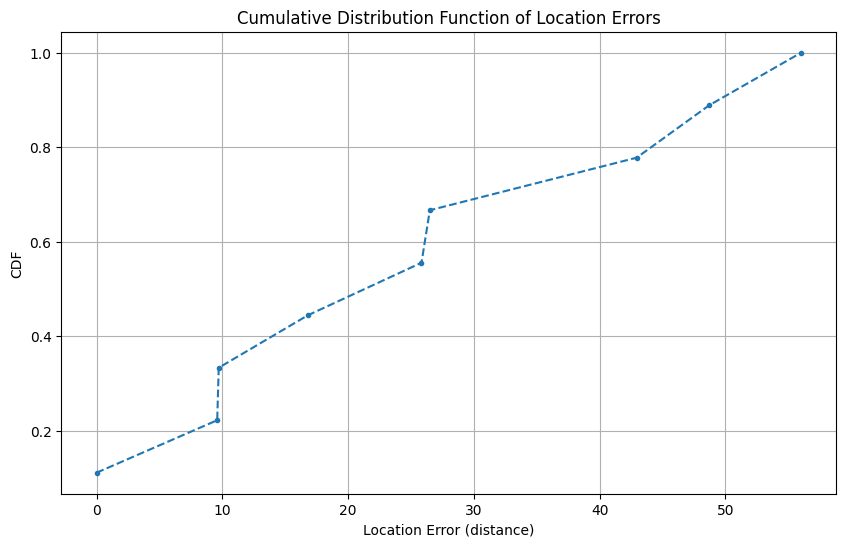

Total sequences: 9
Mean error: 26.23 units
Median error: 25.84 units
Max error: 56.01 units


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt
import math
from math import radians, sin, cos, sqrt, atan2


def classical_estimate_location(sequence, access_points, points, M, T=0):
    """
    Classical pattern matching with Hamming distance threshold T
    Returns the estimated location by averaging all matching positions
    """
    estimated_locations = []

    for ap_id, pattern in sequence.items():
        ap_estimated_locations = []
        full_list = access_points[ap_id]
        N = len(full_list)
        matches = []

        for i in range(N - M + 1):
          hamming_dist = sum(full_list[i + j] != pattern[j] for j in range(M))
          if hamming_dist <= T:
            matches.append(i)
            # estimated_locations.append(points[i])
            ap_estimated_locations.append((points[i], 1/(hamming_dist+.00001)))

        max_tuple = max(ap_estimated_locations, key=lambda item: item[1])
        estimated_locations.append(max_tuple) # ThINK ABOUT THE SEQUENCE LENGTH, M, N, 1, K 1->INF
            # break   # xxxxxxx


    # Average all AP estimates
    total_prob = sum(prob for _, prob in estimated_locations)
    final_x = sum(p[0]* prob for p,prob in estimated_locations) / total_prob
    final_y = sum(p[1]*prob for p,prob in estimated_locations) / total_prob

    # total_prob = sum(prob for _, prob in estimated_locations)
    # avg_x = sum(p[0]*prob for p, prob in estimated_locations) / total_prob # xxxxxxxx
    # avg_y = sum(p[1]*prob for p, prob in estimated_locations) / total_prob # xxxxxxxx

    return (final_x, final_y)

def calculate_distance(p1, p2):
    return sqrt((p1[0] - p2[0])**2 + (p1[1] - p2[1])**2)

def haversine_distance(point1, point2):
    """
    Calculate the great-circle distance (in meters) between two GPS points using the Haversine formula.

    Args:
        point1 (tuple): (latitude, longitude) of first point in degrees
        point2 (tuple): (latitude, longitude) of second point in degrees

    Returns:
        float: Distance in meters
    """
    lat1, lon1 = point1
    lat2, lon2 = point2

    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat / 2)**2 + cos(lat1) * cos(lat2) * sin(dlon / 2)**2
    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    # Earth radius in meters (mean radius = 6371 km)
    R = 6371e3  # 6371 km * 1000 m/km

    distance = R * c
    return distance


def plot_cdf(errors):
    sorted_errors = np.sort(errors)
    cdf = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)

    plt.figure(figsize=(10, 6))
    plt.plot(sorted_errors, cdf, marker='.', linestyle='--')
    plt.xlabel('Location Error (distance)')
    plt.ylabel('CDF')
    plt.title('Cumulative Distribution Function of Location Errors')
    plt.grid(True)
    plt.show()

def main():
    M = 3  # Sequence length
    T = 0.0
    # file_path = 'indoor_avg.txt'

    # Parse the data
    # points, access_points = parse_wifi_data(file_path)
    train_x_file = "./dataset/train_x.txt"
    train_y_file = "./dataset/train_y.txt"

    # Load data
    train_x, train_y = load_data(train_x_file, train_y_file)

    # Verify data shapes
    print(f"Train X shape: {train_x.shape}")
    print(f"Train Y shape: {train_y.shape}")
    print(f"Number of samples: {len(train_x)}")

    # Process data
    points, access_points = process_data(train_x, train_y)

    # Generate sequences
    sequences, ground_truth = generate_sequences(M, points, access_points) #generate_sequences(M)

    # Estimate locations and calculate errors
    errors = []
    for seq, truth in zip(sequences, ground_truth):
        estimated_loc = classical_estimate_location(seq, access_points, points, M, T=T)
        if estimated_loc:
            error = haversine_distance(estimated_loc, truth)
            errors.append(error)

    # Plot CDF
    plot_cdf(errors)

    # Print some statistics
    print(f"Total sequences: {len(sequences)}")
    print(f"Mean error: {np.mean(errors):.2f} units")
    print(f"Median error: {np.median(errors):.2f} units")
    print(f"Max error: {np.max(errors):.2f} units")

if __name__ == "__main__":
    main()

Train X shape: (5500, 21)
Train Y shape: (5500, 2)
Number of samples: 5500
Processing sequence 1


C:\Users\Aleem Raza\AppData\Local\Temp\ipykernel_10112\3967391074.py:53: DeprecationWarning: The class ``qiskit.circuit.library.generalized_gates.diagonal.Diagonal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use DiagonalGate instead.
  oracle = Diagonal(diagonal)
C:\Users\Aleem Raza\AppData\Local\Temp\ipykernel_10112\3967391074.py:53: DeprecationWarning: The class ``qiskit.circuit.library.generalized_gates.diagonal.Diagonal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use DiagonalGate instead.
  oracle = Diagonal(diagonal)


Estimated: (31.265194181818185, 30.003909681818183), Truth: (31.265377, 30.003767), Error: 24.44
Processing sequence 2
Estimated: (31.264669625, 30.004471375000005), Truth: (31.264477, 30.004704), Error: 30.78
Processing sequence 3
Estimated: (31.264853923076927, 30.00392615384616), Truth: (31.26485, 30.004092), Error: 15.77
Processing sequence 4
Estimated: (31.26511566666667, 30.00348333333334), Truth: (31.265127, 30.003481), Error: 1.28
Processing sequence 5
Estimated: (31.26540436666667, 30.002823733333337), Truth: (31.265482, 30.002833), Error: 8.68
Processing sequence 6
Estimated: (31.264832964285713, 30.001918749999998), Truth: (31.264859, 30.001793), Error: 12.30
Processing sequence 7
Estimated: (31.26452900000001, 30.002472500000007), Truth: (31.264512, 30.002403), Error: 6.87
Processing sequence 8
Estimated: (31.264206599999998, 30.003037133333343), Truth: (31.264123, 30.002985), Error: 10.53


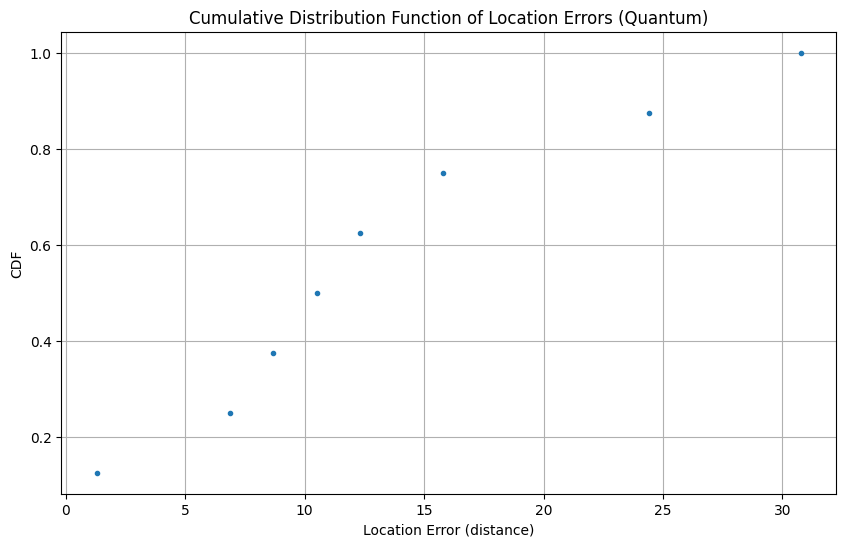


Statistics for first 8 sequences:
Mean error: 13.83 units
Median error: 11.42 units
Max error: 30.78 units


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt, log2, ceil
from qiskit import QuantumCircuit, transpile
from qiskit_aer import Aer
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import Diagonal

def grover_pattern_match(pattern, full_list, T=0, shots=2):
    """
    Quantum pattern matching using Grover's algorithm with classical oracle
    that flips phase of states with Hamming distance <= T.
    """


    N = len(full_list)
    M = len(pattern)

    if (M < T): T = M

    # Number of qubits needed for indices (0 to N-M)
    n_index = ceil(log2(N - M + 1)) if N > M else 1

    # Create quantum circuit
    qc = QuantumCircuit(n_index, n_index)

    # Initialize superposition of indices
    qc.h(range(n_index))

    # Number of Grover iterations
    # num_solutions = len([i for i in range(N - M + 1)
                      # if sum(full_list[i + j] != pattern[j] for j in range(M)) <= T])

    # Precompute which states should have phase flipped
    num_solutions = 0
    phase_flip_indices = []
    for i in range(N - M + 1):
        hamming_dist = sum(full_list[i + j] != pattern[j] for j in range(M))
        if hamming_dist <= T:
            phase_flip_indices.append(i)
            num_solutions += 1

    num_iterations = int(np.pi/4 * np.sqrt((2**n_index)/num_solutions)) if num_solutions > 0 else 0
    # Create diagonal unitary for phase flips
    diagonal = np.ones(2**n_index)
    for idx in phase_flip_indices:
        if idx < 2**n_index:
            diagonal[idx] = -1

    # Grover iterations
    for _ in range(num_iterations):
        # Oracle
        oracle = Diagonal(diagonal)
        qc.append(oracle, range(n_index))

        # Diffusion operator
        qc.h(range(n_index))
        qc.x(range(n_index))
        qc.h(n_index - 1)
        qc.mcx(list(range(n_index - 1)), n_index - 1)
        qc.h(n_index - 1)
        qc.x(range(n_index))
        qc.h(range(n_index))

    # Measure the index qubits
    qc.measure(range(n_index), range(n_index))

    # Execute the circuit
    backend = Aer.get_backend('qasm_simulator')
    compiled_circuit = transpile(qc, backend)
    result = backend.run(compiled_circuit, shots=shots).result()
    counts = result.get_counts()

    # Process results
    matches = []
    for idx_str, count in counts.items():
        idx = int(idx_str, 2)
        if idx < N - M + 1:
            matches.append((idx, count/shots))

    return sorted(matches, key=lambda x: -x[1])

def quantum_estimate_location(sequence, access_points, points, M, T=0):
    estimated_locations = []

    for ap_id, pattern in sequence.items():
        full_list = access_points[ap_id]
        matches = grover_pattern_match(pattern, full_list, T)

        for match_idx, prob in matches:
            if prob > 0.0:  # Only consider matches with significant probability.  xxxxxxxx prob > 0.1
                estimated_locations.append((points[match_idx], prob))
                # break

    if not estimated_locations:
        return None

    # Weighted average based on probabilities
    total_prob = sum(prob for _, prob in estimated_locations)
    avg_x = sum(p[0]*prob for p, prob in estimated_locations) / total_prob # xxxxxxxx
    avg_y = sum(p[1]*prob for p, prob in estimated_locations) / total_prob # xxxxxxxx
    # p , _ = estimated_locations[1]
    # avg_x = p[0]
    # avg_y = p[1]
    # avg_x = (estimated_locations[0])[0]
    # avg_y = (estimated_locations[0])[1]


    # avg_x = sum(p[0] for p, prob in estimated_locations) / len(estimated_locations)
    # avg_y = sum(p[1] for p, prob in estimated_locations) / len(estimated_locations)

    return (avg_x, avg_y)

def plot_cdf(errors):
    sorted_errors = np.sort(errors)
    cdf = np.arange(1, len(sorted_errors)+1) / len(sorted_errors)

    plt.figure(figsize=(10, 6))
    plt.plot(sorted_errors, cdf, marker='.', linestyle='none')
    plt.xlabel('Location Error (distance)')
    plt.ylabel('CDF')
    plt.title('Cumulative Distribution Function of Location Errors (Quantum)')
    plt.grid(True)
    plt.show()

def main():
    M = 4  # Sequence length
    T = 0.0   # Matching threshold
    train_x_file = "./dataset/train_x.txt"
    train_y_file = "./dataset/train_y.txt"

    # Load data
    train_x, train_y = load_data(train_x_file, train_y_file)

    # Verify data shapes
    print(f"Train X shape: {train_x.shape}")
    print(f"Train Y shape: {train_y.shape}")
    print(f"Number of samples: {len(train_x)}")

    # Process data
    points, access_points = process_data(train_x, train_y)

    # Generate sequences
    sequences, ground_truth = generate_sequences(M, points, access_points) #generate_sequences(M)


    # Estimate locations using quantum search and calculate errors
    errors = []
    for seq, truth in zip(sequences[:], ground_truth[:]):  # Just do first 10 for demo
        print(f"Processing sequence {len(errors)+1}")
        estimated_loc = quantum_estimate_location(seq, access_points, points, M, T)
        if estimated_loc:
            error = haversine_distance(estimated_loc, truth)
            errors.append(error)
            print(f"Estimated: {estimated_loc}, Truth: {truth}, Error: {error:.2f}")

    # Plot CDF
    plot_cdf(errors)

    # Print some statistics
    if errors:
        print(f"\nStatistics for first {len(errors)} sequences:")
        print(f"Mean error: {np.mean(errors):.2f} units")
        print(f"Median error: {np.median(errors):.2f} units")
        print(f"Max error: {np.max(errors):.2f} units")
    else:
        print("No valid matches found")

if __name__ == "__main__":
    main()
     

Train X shape: (5500, 21)
Train Y shape: (5500, 2)
Number of samples: 5500


C:\Users\Aleem Raza\AppData\Local\Temp\ipykernel_10112\3967391074.py:53: DeprecationWarning: The class ``qiskit.circuit.library.generalized_gates.diagonal.Diagonal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use DiagonalGate instead.
  oracle = Diagonal(diagonal)


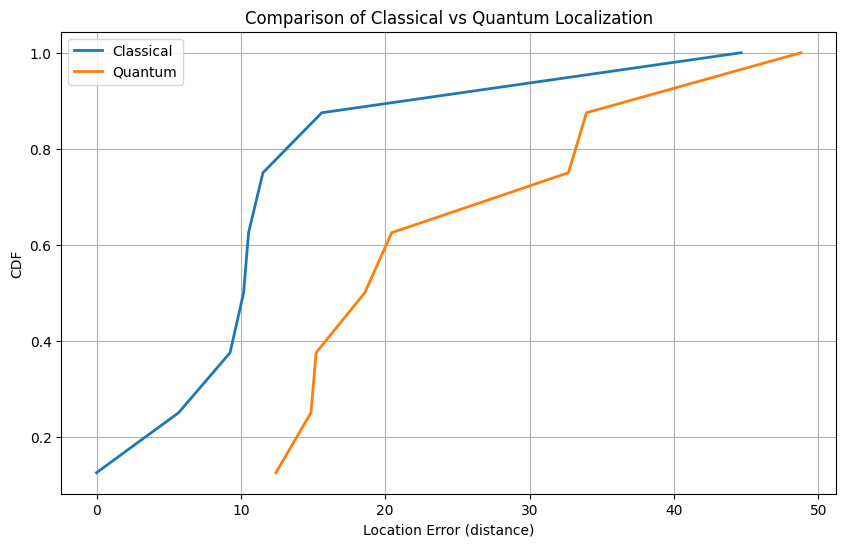

Classical Stats:
Mean error: 13.43, Median: 10.36

Quantum Stats:
Mean error: 24.62, Median: 19.52


In [13]:
import matplotlib.pyplot as plt
import numpy as np
from math import sqrt

def plot_combined_cdf(classical_errors, quantum_errors):
    """
    Plot CDFs for both classical and quantum localization errors
    """
    plt.figure(figsize=(10, 6))

    # Classical CDF
    sorted_classical = np.sort(classical_errors)
    cdf_classical = np.arange(1, len(sorted_classical)+1) / len(sorted_classical)
    plt.plot(sorted_classical, cdf_classical, label='Classical', linewidth=2)

    # Quantum CDF
    sorted_quantum = np.sort(quantum_errors)
    cdf_quantum = np.arange(1, len(sorted_quantum)+1) / len(sorted_quantum)
    plt.plot(sorted_quantum, cdf_quantum, label='Quantum', linewidth=2)

    plt.xlabel('Location Error (distance)')
    plt.ylabel('CDF')
    plt.title('Comparison of Classical vs Quantum Localization')
    plt.legend()
    plt.grid(True)
    plt.show()



# IBM_TOKEN = "not_needed_for_fake_backend"  # Fake backend doesn't need real token
# IBM_INSTANCE = "not_needed"
# aer_sim = get_noisy_aer_simulator(IBM_TOKEN, IBM_INSTANCE, "ibm_brisbane")

M = 4  # Sequence length
T = 0.0   # Matching threshold
train_x_file = "./dataset/train_x.txt"
train_y_file = "./dataset/train_y.txt"

# Load data
train_x, train_y = load_data(train_x_file, train_y_file)

# Verify data shapes
print(f"Train X shape: {train_x.shape}")
print(f"Train Y shape: {train_y.shape}")
print(f"Number of samples: {len(train_x)}")

# Process data
points, access_points = process_data(train_x, train_y)

# Generate sequences
sequences, ground_truth = generate_sequences(M, points, access_points) #generate_sequences(M)

# Limit to first 20 sequences for demonstration
sequences = sequences[:]
ground_truth = ground_truth[:]

# Classical localization
classical_errors = []
for seq, truth in zip(sequences, ground_truth):
        estimated_loc = classical_estimate_location(seq, access_points, points, M, T)
        if estimated_loc:
            error = haversine_distance(estimated_loc, truth)
            classical_errors.append(error)

    # Quantum localization
quantum_errors = []
for seq, truth in zip(sequences, ground_truth):
        # estimated_loc = quantum_estimate_location(seq, access_points, points, M, T)
        estimated_loc = quantum_estimate_location(seq, access_points, points, M, T)
        if estimated_loc:
            error = haversine_distance(estimated_loc, truth)
            quantum_errors.append(error)

# Plot combined CDF
plot_combined_cdf(classical_errors, quantum_errors)

# Print statistics
print("Classical Stats:")
print(f"Mean error: {np.mean(classical_errors):.2f}, Median: {np.median(classical_errors):.2f}")

print("\nQuantum Stats:")
print(f"Mean error: {np.mean(quantum_errors):.2f}, Median: {np.median(quantum_errors):.2f}")